# phase 2 :
    1- loading , spliting , training the models then evaluating 

In [5]:
from prepration import load_data , check_data , split_data

df= load_data()
check_data(df)

Shape: (10299, 565)
Duplicate rows: 0
Missing values: 0


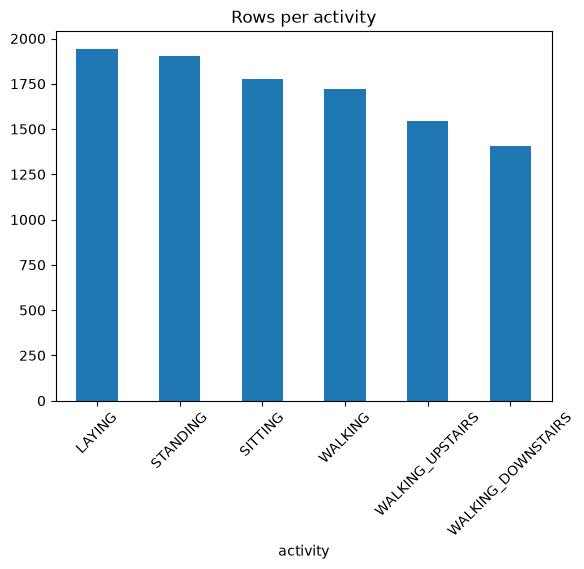

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

df["activity"].value_counts().plot(kind="bar", title="Rows per activity")
plt.xticks(rotation=45)
plt.show()

In [7]:
X_train , y_train ,groups_train, X_test , y_test = split_data(df)

print("train :" , X_train.shape , "test :" , X_test.shape)
print("Overlap:", set(groups_train) & set(df.loc[X_test.index, "subject_id"]))

train : (7352, 561) test : (2947, 561)
Overlap: set()


In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


ridge = make_pipeline(StandardScaler() , LogisticRegression(max_iter=5000))
lasso = make_pipeline(StandardScaler() , LogisticRegression(l1_ratio=1 , solver = "saga" , tol = 0.01 , random_state=35))

models = {"ridge" : ridge , "lasso" : lasso}

for name , model in models.items() : 
    model.fit(X_train , y_train)
    print(name , "zero weights :" , (model[-1].coef_ == 0).sum() , "of" , model[-1].coef_.size)


ridge zero weights : 0 of 3366
lasso zero weights : 51 of 3366


In [11]:
from sklearn.metrics import accuracy_score, classification_report

for name, model in models.items():
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    print(f"{name}")
    print(f"Test Accuracy: {acc * 100}%")
    print(classification_report(y_test, y_pred))

ridge
Test Accuracy: 95.62266711910418%
                    precision    recall  f1-score   support

            LAYING       1.00      0.99      0.99       537
           SITTING       0.97      0.88      0.92       491
          STANDING       0.89      0.98      0.93       532
           WALKING       0.95      0.99      0.97       496
WALKING_DOWNSTAIRS       0.99      0.94      0.97       420
  WALKING_UPSTAIRS       0.96      0.95      0.96       471

          accuracy                           0.96      2947
         macro avg       0.96      0.96      0.96      2947
      weighted avg       0.96      0.96      0.96      2947

lasso
Test Accuracy: 94.33322022395657%
                    precision    recall  f1-score   support

            LAYING       1.00      0.98      0.99       537
           SITTING       0.93      0.89      0.91       491
          STANDING       0.88      0.94      0.91       532
           WALKING       0.94      0.99      0.96       496
WALKING_DOWNSTAI

In [12]:
from sklearn.model_selection import GroupKFold, cross_val_score

gkf = GroupKFold(n_splits=5)

for name, model in models.items():
    cv_scores = cross_val_score(
        model, X_train, y_train, cv=gkf, groups=groups_train, scoring="accuracy"
    )
    print(f"=== {name.upper()} (5-Fold Group CV) ===")
    print("Fold accuracies:", [round(s * 100, 2) for s in cv_scores])
    print(f"Mean CV Accuracy: {cv_scores.mean() * 100:.2f}% (+/- {cv_scores.std() * 100:.2f}%)\n")

=== RIDGE (5-Fold Group CV) ===
Fold accuracies: [np.float64(88.17), np.float64(89.86), np.float64(97.95), np.float64(97.09), np.float64(94.3)]
Mean CV Accuracy: 93.48% (+/- 3.87%)

=== LASSO (5-Fold Group CV) ===
Fold accuracies: [np.float64(86.69), np.float64(89.72), np.float64(97.81), np.float64(96.52), np.float64(91.63)]
Mean CV Accuracy: 92.48% (+/- 4.16%)



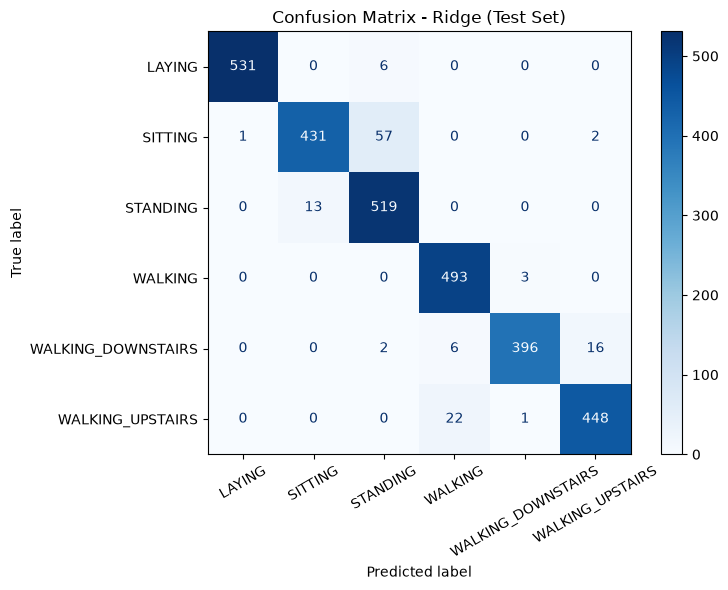

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

best_model = models["ridge"]
y_pred_best = best_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred_best, labels=best_model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=best_model.classes_)

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=30)
plt.title("Confusion Matrix - Ridge (Test Set)")
plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path
import joblib

model_path = Path("ridge_model.pkl")
joblib.dump(models["ridge"], model_path)

Saved model to: C:\Users\User\Desktop\Uni\Projects\IoT Machine Learning\ML_project\phase2\ridge_model.pkl
